# Notebook 04 · Resultados, comparaciones y figuras

**Pregunta:** ¿cómo se comparan las estrategias sobre los mismos distritos y meses?

**Entradas:** configuración, scores y pronósticos registrados. **Salidas:** métricas por distrito,
contrastes E1–E10, seis tablas del paper y diez figuras con sus datos y descripciones.
Esta notebook analiza pronósticos guardados; no entrena modelos ni selecciona hiperparámetros.

La ruta es **validar → reconstruir un error → comparar pares → interpretar → exportar**.
Cada figura se construye junto al cálculo que la sustenta. E1 conserva su papel principal;
las extensiones Δz, SES y los análisis posteriores mantienen su estatus exploratorio o post hoc.

Usa el mismo `PROJECT_DIR` y la misma `CARPETA_RESULTADOS` que en 02 y 03.
Para leer la corrida incluida, conserva `MODO = 'revisar'` y `CARPETA_RESULTADOS = 'resultados'`.

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    PROJECT_DIR = Path.cwd()  # En local, abrir desde la carpeta SIDPOL_Notebooks.
else:
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks')

MODO = 'revisar'  # Notebook 04 siempre analiza pronósticos guardados; nunca entrena.
CARPETA_RESULTADOS = 'resultados'
sys.path.insert(0, str(PROJECT_DIR))
import sidpol as sp
import sidpol_figuras as sf

sp.require(MODO == 'revisar', 'Notebook 04 no entrena modelos.')
P, ENV, panel, Q, districts = sp.setup(PROJECT_DIR, CARPETA_RESULTADOS)
if MODO == 'reentrenar':
    sp.require(CARPETA_RESULTADOS != 'resultados', 'Use otra carpeta para no sobrescribir la corrida entregada.')
    sp.require_training_environment(ENV)

print(f'Modo: {MODO} | Carpeta: {P.root / CARPETA_RESULTADOS}')
print('Entorno de esta ejecución:', ENV)
registros_figuras = []

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks/sidpol.py:97: UserWarning: Versiones distintas de requirements_modelado.txt (esperada, actual): {'numpy': ('2.1.3', '2.4.6')}. En modo revisar se verifican archivos guardados y se registra este entorno. No se está reproduciendo el entrenamiento. Consulte README.md.
  warnings.warn(f'Versiones distintas de requirements_modelado.txt (esperada, actual): {wrong}. '


Modo: revisar | Carpeta: /content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks/resultados
Entorno de esta ejecución: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'xgboost': '3.4.1', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}


## 1. Validar antes de renovar las salidas

Se verifican la cadena configuración → pronósticos, la tabla de scores, la cobertura por claves y los valores observados.
**Solo después** se renueva la carpeta `04_resultados` dentro de `CARPETA_RESULTADOS`. Los archivos de 01–03 se conservan.
El entorno de este reanálisis se registra aparte del entorno del entrenamiento recibido.

In [3]:
import shutil
config, fc_all, main = sp.load_results_inputs(P, Q)
sp.check_config_contract(config)
sp.check_forecasts(fc_all, panel, districts, config['e3_excluded_ubigeo'])
sp.require((fc_all.cutoff == fc_all.forecast_month - pd.DateOffset(months=1)).all(), 'Cutoff inválido.')

# Ninguna carpeta se borra si alguna comprobación anterior falla.
if P.analysis.exists():
    shutil.rmtree(P.analysis)
TAB = P.analysis / 'tablas'
PAPER = P.analysis / 'paper'
FIG = PAPER / 'figuras'
TAB.mkdir(parents=True, exist_ok=True)

dm = sp.district_metrics(main)
MASE = dm.set_index(['target', 'strategy', 'UBIGEO']).MASE.sort_index()
MAE = dm.set_index(['target', 'strategy', 'UBIGEO']).MAE.sort_index()
sp.write_csv(TAB / 'metricas_por_distrito.csv', dm)
print(f'{len(fc_all):,} pronósticos verificados. Solo se regeneran los resultados de análisis.')

44,290 pronósticos verificados. Solo se regeneran los resultados de análisis.


## 2. Reconstruir un MASE real

Para un target fijo, $d$ identifica el distrito. La auditoría utiliza los 60 meses de enero de 2018 a diciembre de 2022
para calcular una escala de error estacional, con 48 diferencias de 12 meses:

$$
Q_d=\frac{1}{60-12}\sum_{u=13}^{60}\lvert y_{d,u}-y_{d,u-12}\rvert.
$$

En esa fórmula, $u=1$ corresponde a enero de 2018. La constante se carga como `Q_j` y se mantiene fija.
Para una estrategia $m$ y un conjunto de meses evaluados $\mathcal{T}$:

$$
\operatorname{MASE}_{d,m}(\mathcal{T})
=\frac{1}{\lvert\mathcal{T}\rvert}\sum_{t\in\mathcal{T}}
\frac{\lvert y_{d,t}-\widehat{y}^{(m)}_{d,t}\rvert}{Q_d}.
$$

Es la **media del error absoluto dividida por Q_d**. En el periodo externo completo,
$\lvert\mathcal{T}\rvert=43$; en otros cortes se utiliza su número de meses correspondiente.
Un MASE menor que 1 no implica superar a naïve-1: la escala procede de una referencia estacional histórica.
La comparación con un método exige evaluar sus errores sobre los mismos casos.

El ejemplo usa los 43 meses del distrito central por volumen mediano de 2018–2022, no un caso elegido por su error.

In [4]:
casos = sp.example_districts(panel)
target_ejemplo = 'ROBO'
ubigeo_ejemplo = str(casos.loc[casos.target == target_ejemplo, 'UBIGEO'].iloc[0])
ejemplo = main[(main.target == target_ejemplo) & (main.UBIGEO == ubigeo_ejemplo)
               & (main.strategy == 'local_HL')].sort_values('forecast_month').copy()
ejemplo['Q_j'] = Q[(target_ejemplo, ubigeo_ejemplo)]
ejemplo['error_absoluto_manual'] = (ejemplo.y_true - ejemplo.y_pred).abs()
ejemplo['error_escalado_manual'] = ejemplo.error_absoluto_manual / ejemplo.Q_j
mase_manual = ejemplo.error_escalado_manual.mean()
mase_tabla = MASE.loc[target_ejemplo, 'local_HL', ubigeo_ejemplo]
sp.require(len(ejemplo) == 43 and np.isclose(mase_manual, mase_tabla, atol=1e-12, rtol=0), 'MASE manual diferente.')
display(ejemplo[['forecast_month', 'y_true', 'y_pred', 'Q_j', 'error_absoluto_manual', 'error_escalado_manual']].head(8))
print(f'MASE sobre los 43 meses: {mase_manual:.6f}. Coincide con la tabla final.')
sp.write_csv(TAB / 'ejemplo_mase_manual.csv', ejemplo)
display(sp.overview(dm))

,forecast_month,y_true,y_pred,Q_j,error_absoluto_manual,error_escalado_manual
20273,2023-01-01,36.0,36.918411,25.604167,0.918411,0.035870
20316,2023-02-01,36.0,41.208843,25.604167,5.208843,0.203437
20359,2023-03-01,39.0,42.460747,25.604167,3.460747,0.135163
20402,2023-04-01,60.0,28.635359,25.604167,31.364641,1.224982
20445,2023-05-01,52.0,60.537987,25.604167,8.537987,0.333461
20488,2023-06-01,59.0,40.195694,25.604167,18.804306,0.734424
20531,2023-07-01,37.0,60.919487,25.604167,23.919487,0.934203
20574,2023-08-01,47.0,43.475441,25.604167,3.524559,0.137656


MASE sobre los 43 meses: 0.354653. Coincide con la tabla final.


target,Robo,Hurto
MASE mediano (43 distritos),,
Naïve-1,0.528,0.568
Naïve estacional,1.269,1.164
SES,0.536,0.566
SES + ½ pendiente (ad hoc),0.536,0.566
Local · niveles,0.642,0.693
Global · niveles (H_L),0.584,0.632
Global · niveles (H_G),0.579,0.606
Local · Δz,0.519,0.568
Global · Δz (H_L5),0.535,0.574


## 3. Comparación pareada: Global − Local (E1 principal, E1b sensibilidad)

Primero se calcula **una diferencia por distrito** y después se resumen las 43 diferencias:

$$
\delta_d=\operatorname{MASE}_{d,\mathrm{Global}}-\operatorname{MASE}_{d,\mathrm{Local}},
\qquad
\widetilde{\delta}=\operatorname{mediana}_{d=1,\ldots,43}(\delta_d).
$$

Un valor negativo favorece a Global. La **mediana de las diferencias** no tiene que coincidir con la
**diferencia entre medianas**. E1 comparte H_L; E1b usa H_G para Global y mantiene H_L para Local.

Los IC95 se obtienen con 5,000 remuestreos de pares distritales, semilla 42, y sus percentiles 2.5 y 97.5.
Wilcoxon utiliza rangos con signo y Holm ajusta los dos targets dentro de cada contraste.
El intervalo y la prueba no son dos versiones de una misma prueba de la mediana ni demuestran equivalencia.
Los distritos pueden compartir shocks y dependencia espacial; el bootstrap empleado no elimina esa limitación.

In [5]:
contrasts, pairs = sp.global_vs_local(MASE)
sp.write_csv(TAB / 'contrastes_global_local.csv', contrasts)
sp.write_csv(TAB / 'pares_distritales.csv', pairs)
pares_ejemplo = pairs[(pairs.experiment == 'E1') & (pairs.target == target_ejemplo)].copy()
pares_ejemplo['diferencia_manual'] = pares_ejemplo.MASE_A - pares_ejemplo.MASE_B
sp.require(np.allclose(pares_ejemplo.delta, pares_ejemplo.diferencia_manual, atol=sp.TIE_TOL, rtol=0), 'Pares inconsistentes.')
display(pares_ejemplo[['UBIGEO', 'MASE_A', 'MASE_B', 'delta']].head(8))
print('Mediana de diferencias:', pares_ejemplo.delta.median())
print('Diferencia entre medianas:', pares_ejemplo.MASE_A.median() - pares_ejemplo.MASE_B.median())
display(sp.view_contrasts(contrasts, ['E1', 'E1b']))

,UBIGEO,MASE_A,MASE_B,delta
0,150101,0.655956,0.641634,0.014322
1,150102,0.647443,0.663887,-0.016443
2,150103,0.813629,1.018381,-0.204753
3,150104,0.277009,0.343229,-0.066221
4,150105,0.735550,0.766567,-0.031018
5,150106,0.270467,0.351518,-0.081051
6,150107,0.821091,0.936199,-0.115109
7,150108,0.454649,0.484352,-0.029702


Mediana de diferencias: -0.08105132987360597
Diferencia entre medianas: -0.05775570627915838


Mediana ΔMASE [IC95]  \
Contraste                                Delito                            
E1 · Global − Local, niveles (misma H_L) Robo    −0.081 [−0.099; −0.058]   
                                         Hurto   −0.066 [−0.091; −0.046]   
E1b · Global (H_G) − Local, niveles      Robo    −0.070 [−0.082; −0.050]   
                                         Hurto   −0.069 [−0.108; −0.035]   

                                                A mejor en   p Holm  
Contraste                                Delito                      
E1 · Global − Local, niveles (misma H_L) Robo        36/43  6.1e-06  
                                         Hurto       34/43  0.00013  
E1b · Global (H_G) − Local, niveles      Robo        33/43  4.1e-08  
                                         Hurto       36/43  4.5e-07

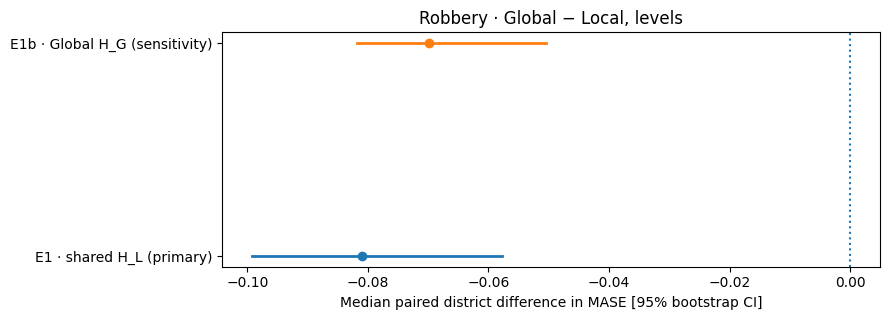

Fuente: contrasts calculado en esta sección. Diferencia Global − Local; negativo favorece a Global. 43 pares distritales. Los IC suponen el remuestreo distrital definido, no independencia demostrada.
Datos de esta figura: fig1_E1_robo_datos.csv


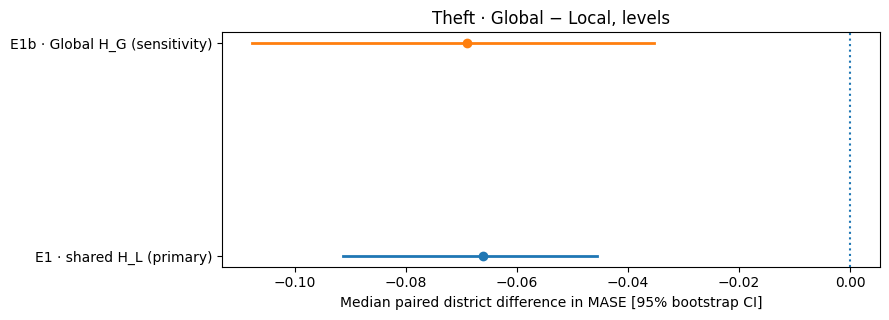

Fuente: contrasts calculado en esta sección. Diferencia Global − Local; negativo favorece a Global. 43 pares distritales. Los IC suponen el remuestreo distrital definido, no independencia demostrada.
Datos de esta figura: fig1_E1_hurto_datos.csv


In [6]:
for target in sp.TARGETS:
    datos_grafico = contrasts[(contrasts.target == target) & contrasts.experiment.isin(['E1', 'E1b'])].copy()
    datos_grafico = datos_grafico.set_index('experiment').loc[['E1', 'E1b']].reset_index()
    datos_grafico['etiqueta'] = ['E1 · shared H_L (primary)', 'E1b · Global H_G (sensitivity)']
    fig, ax = plt.subplots(figsize=(9, 3.3))
    for i, row in enumerate(datos_grafico.itertuples()):
        ax.plot([row.CI95_low, row.CI95_high], [i, i], linewidth=2)
        ax.scatter(row.median_delta, i, marker='o')
    ax.axvline(0, linestyle=':')
    ax.set_yticks(range(len(datos_grafico)), datos_grafico.etiqueta)
    ax.set(title=f'{sp.TARGET_EN[target]} · Global − Local, levels',
           xlabel='Median paired district difference in MASE [95% bootstrap CI]')
    registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG, f'fig1_E1_{target.lower()}',
        'Fuente: contrasts calculado en esta sección. Diferencia Global − Local; negativo favorece a Global. '
        '43 pares distritales. Los IC suponen el remuestreo distrital definido, no independencia demostrada.',
        '04', '3. E1/E1b'))

**Para interpretar:** identifica la dirección de E1 por target y revisa el intervalo. Mejorar frente a Local
no implica superar a las referencias simples; esa comparación se examina a continuación.

## 4. Referencias simples: naïve-1 y SES

Naïve-1 repite el último mes. SES es una referencia estadística incorporada post hoc, ajustada sobre `log1p(y)`
con el historial anterior a cada mes y posteriormente transformada a denuncias.
La tabla contiene comparaciones frente a ambos métodos. Los gráficos de esta sección muestran **A − naïve-1**;
la comparación **A − SES** se consulta en la tabla.

Las columnas de MASE y MAE son medianas descriptivas entre distritos. Las columnas A − B muestran
medianas de diferencias pareadas, con una interpretación distinta.

MASE mediano       A − Naïve-1 [IC95]  \
Delito Estrategia (A)                                                  
Robo   Local · niveles                0.642  +0.088 [+0.076; +0.137]   
       Global · niveles (H_L)         0.584  +0.024 [−0.008; +0.047]   
       Local · Δz                     0.519  −0.002 [−0.010; +0.005]   
       Global · Δz (H_L5)             0.535  −0.013 [−0.024; −0.003]   
       Global · Δz (H_G5)             0.599  +0.047 [+0.024; +0.070]   
       SES                            0.536       −0.015 [−0.036; 0]   
Hurto  Local · niveles                0.693  +0.087 [+0.050; +0.145]   
       Global · niveles (H_L)         0.632  +0.020 [−0.015; +0.050]   
       Local · Δz                     0.568  −0.003 [−0.022; +0.003]   
       Global · Δz (H_L5)             0.574  −0.025 [−0.030; −0.018]   
       Global · Δz (H_G5)             0.566  −0.030 [−0.036; −0.011]   
       SES                            0.566  −0.026 [−0.047; −0.014]   

                              Mejor que Naïve-1           A − SES [IC95]  
Delito Estrategia (A)                                                     
Robo   Local · niveles                     9/43  +0.122 [+0.084; +0.152]  
       Global · niveles (H_L)             17/43  +0.027 [+0.014; +0.063]  
       Local · Δz                         23/43  +0.009 [−0.004; +0.024]  
       Global · Δz (H_L5)                 30/43  +0.003 [−0.006; +0.017]  
       Global · Δz (H_G5)                 11/43  +0.049 [+0.038; +0.067]  
       SES                                26/43                        —  
Hurto  Local · niveles                     9/43  +0.109 [+0.084; +0.145]  
       Global · niveles (H_L)             19/43  +0.036 [+0.016; +0.052]  
       Local · Δz                         23/43  +0.011 [+0.006; +0.032]  
       Global · Δz (H_L5)                 36/43  +0.007 [−0.003; +0.011]  
       Global · Δz (H_G5)                 35/43  +0.005 [−0.000; +0.014]  
       SES                                31/43                        —

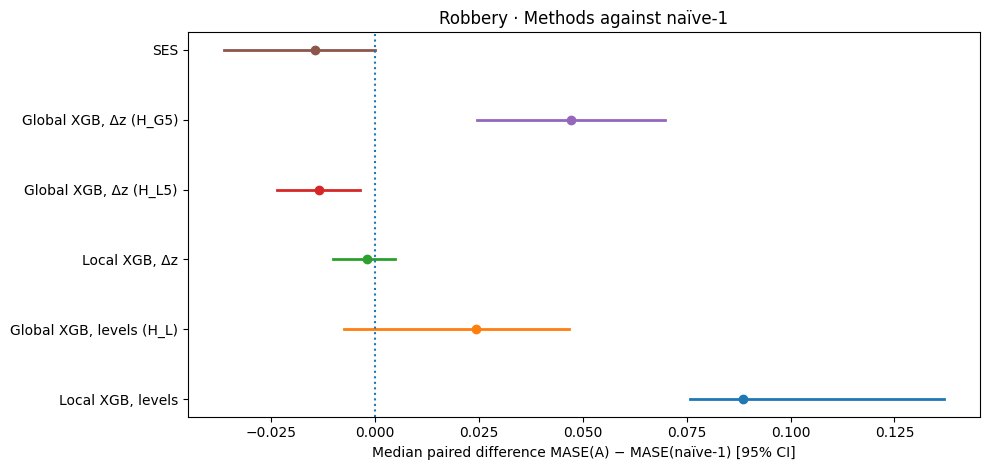

Fuente: e8 calculado desde métricas distritales de esta corrida. Negativo favorece a A. Niveles: estudio principal; Δz: exploratorio; SES: post hoc. No implica equivalencia si el IC incluye cero.
Datos de esta figura: fig2_referencias_robo_datos.csv


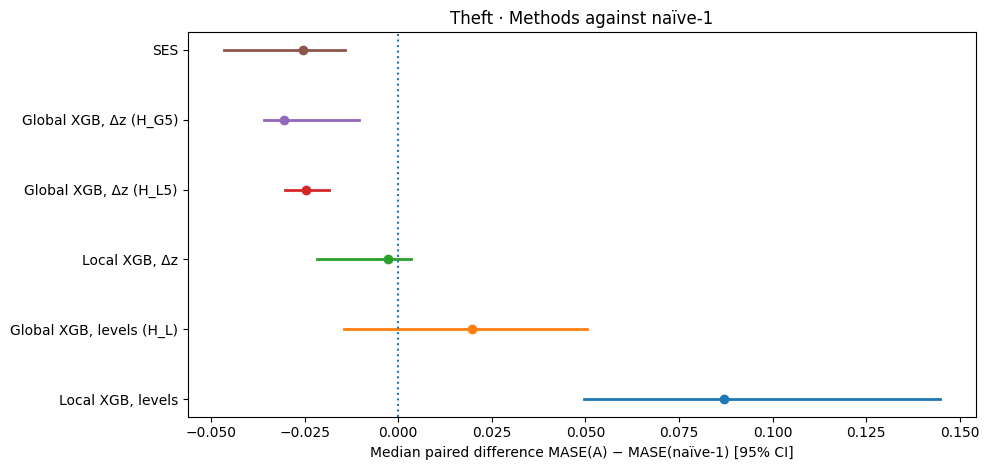

Fuente: e8 calculado desde métricas distritales de esta corrida. Negativo favorece a A. Niveles: estudio principal; Δz: exploratorio; SES: post hoc. No implica equivalencia si el IC incluye cero.
Datos de esta figura: fig2_referencias_hurto_datos.csv


In [7]:
e8, e6 = sp.vs_references(MASE, MAE)
sp.write_csv(TAB / 'E8_todas_las_estrategias.csv', e8)
sp.write_csv(TAB / 'E6_vs_referencias.csv', e6)
metodos_visibles = ['local_HL', 'global_HL', 'local_dz_HL', 'global_dz_HL', 'global_dz_HG', 'ses']
display(sp.view_references(e8, metodos_visibles))
for target in sp.TARGETS:
    datos_grafico = e8[(e8.target == target) & e8.strategy.isin(metodos_visibles)].copy()
    datos_grafico = datos_grafico.set_index('strategy').loc[metodos_visibles].reset_index()
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for i, row in enumerate(datos_grafico.itertuples()):
        ax.plot([row.CI95_low_vs_naive1, row.CI95_high_vs_naive1], [i, i], linewidth=2)
        ax.scatter(row.median_diff_vs_naive1, i, marker='o')
    ax.axvline(0, linestyle=':')
    ax.set_yticks(range(len(datos_grafico)), [sp.NAMES[s] for s in datos_grafico.strategy])
    ax.set(title=f'{sp.TARGET_EN[target]} · Methods against naïve-1',
           xlabel='Median paired difference MASE(A) − MASE(naïve-1) [95% CI]')
    registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG, f'fig2_referencias_{target.lower()}',
        'Fuente: e8 calculado desde métricas distritales de esta corrida. Negativo favorece a A. '
        'Niveles: estudio principal; Δz: exploratorio; SES: post hoc. No implica equivalencia si el IC incluye cero.',
        '04', '4. Referencias simples'))

## 5. Extensión Δz: ¿qué cambia en los pares distritales?

E5 usa H_L5 en ambos modelos; E5b usa H_G5 para Global y H_L5 para Local. Son exploratorios y no reemplazan E1.
Los gráficos muestran **los 43 distritos de E5**, sin recortar puntos. Debajo de la diagonal, Global tiene menor MASE.
E5b se presenta en la tabla, no en esta dispersión. La figura describe heterogeneidad y se interpreta junto con el contraste.

Mediana ΔMASE [IC95]  \
Contraste                            Delito                            
E5 · Global − Local, Δz (misma H_L5) Robo    −0.005 [−0.019; +0.005]   
                                     Hurto   −0.010 [−0.017; +0.001]   
E5b · Global (H_G5) − Local, Δz      Robo    +0.045 [+0.034; +0.062]   
                                     Hurto   −0.011 [−0.023; −0.006]   

                                            A mejor en   p Holm  
Contraste                            Delito                      
E5 · Global − Local, Δz (misma H_L5) Robo        25/43     0.26  
                                     Hurto       27/43     0.26  
E5b · Global (H_G5) − Local, Δz      Robo         6/43  5.8e-07  
                                     Hurto       30/43    0.025

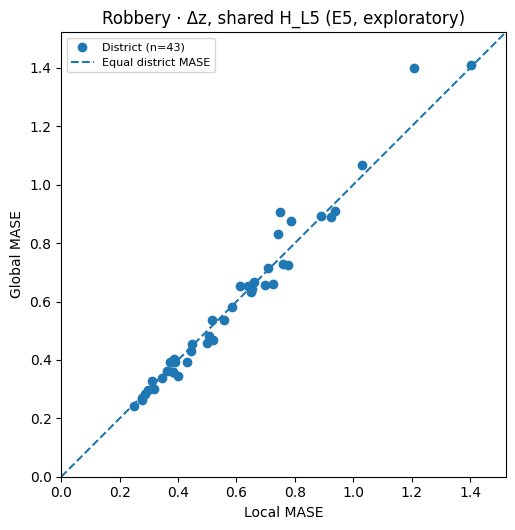

Fuente: pairs calculado en Notebook 04. 43 distritos visibles; ejes derivados de todos los valores. No se seleccionan distritos por su resultado.
Datos de esta figura: fig3_E5_distritos_robo_datos.csv


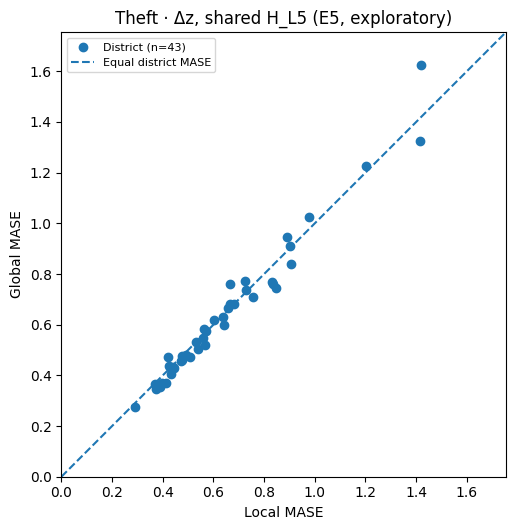

Fuente: pairs calculado en Notebook 04. 43 distritos visibles; ejes derivados de todos los valores. No se seleccionan distritos por su resultado.
Datos de esta figura: fig3_E5_distritos_hurto_datos.csv


In [8]:
display(sp.view_contrasts(contrasts, ['E5', 'E5b']))
for target in sp.TARGETS:
    datos_grafico = pairs[(pairs.target == target) & (pairs.experiment == 'E5')].copy()
    sp.require(len(datos_grafico) == 43 and datos_grafico.UBIGEO.nunique() == 43, 'Faltan pares de E5.')
    limite = float(datos_grafico[['MASE_A', 'MASE_B']].max().max()) * 1.08
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    ax.scatter(datos_grafico.MASE_B, datos_grafico.MASE_A, marker='o', label='District (n=43)')
    ax.plot([0, limite], [0, limite], linestyle='--', label='Equal district MASE')
    ax.set(xlim=(0, limite), ylim=(0, limite), aspect='equal',
           title=f'{sp.TARGET_EN[target]} · Δz, shared H_L5 (E5, exploratory)',
           xlabel='Local MASE', ylabel='Global MASE')
    ax.legend(fontsize=8)
    registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG, f'fig3_E5_distritos_{target.lower()}',
        'Fuente: pairs calculado en Notebook 04. 43 distritos visibles; ejes derivados de todos los valores. '
        'No se seleccionan distritos por su resultado.', '04', '5. E5 por distrito'))

**Para interpretar:** un E1 con evidencia de diferencia y un E5 sin ella no prueban por sí solos un mecanismo
ni la equivalencia de Local y Global. Niveles y Δz difieren en respuesta, variables predictoras y grilla de calibración.

## 6. Resultado por año (E10, post hoc descriptivo)

Primero se calcula el MASE anual por distrito y después la diferencia Global − Local.
Cada punto es la mediana de esos pares; la escala Q_d permanece fija. **2026 incluye solo enero–julio.**
Las comparaciones usan H_L para niveles y H_L5 para Δz. No se agregan pruebas por año.

year                          2023            2024            2025  \
Delito Formulación                                                   
Robo   Niveles      −0.131 (32/43)  −0.086 (33/43)  −0.047 (29/43)   
       Δz           −0.012 (25/43)  −0.003 (23/43)  −0.007 (25/43)   
Hurto  Niveles      −0.157 (35/43)  −0.026 (25/43)  −0.028 (28/43)   
       Δz           −0.025 (32/43)  −0.016 (27/43)  +0.001 (19/43)   

year                          2026  
Delito Formulación                  
Robo   Niveles      −0.014 (25/43)  
       Δz           −0.001 (23/43)  
Hurto  Niveles      −0.053 (29/43)  
       Δz           +0.000 (21/43)

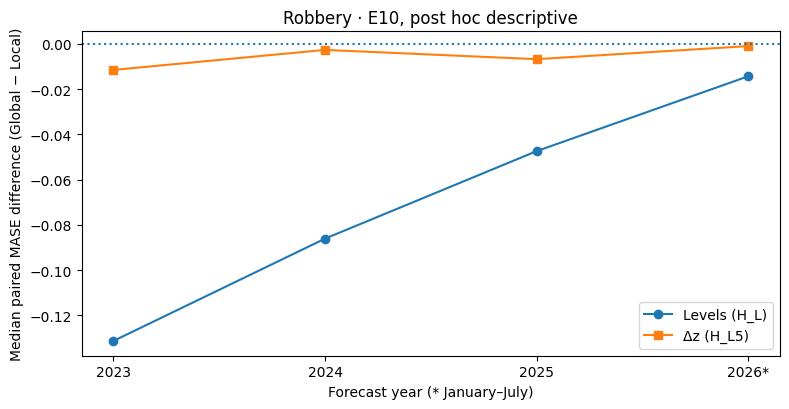

Fuente: e10 calculado desde los pronósticos. 2026 parcial. Evolución descriptiva, no explicación causal.
Datos de esta figura: fig4_anual_robo_datos.csv


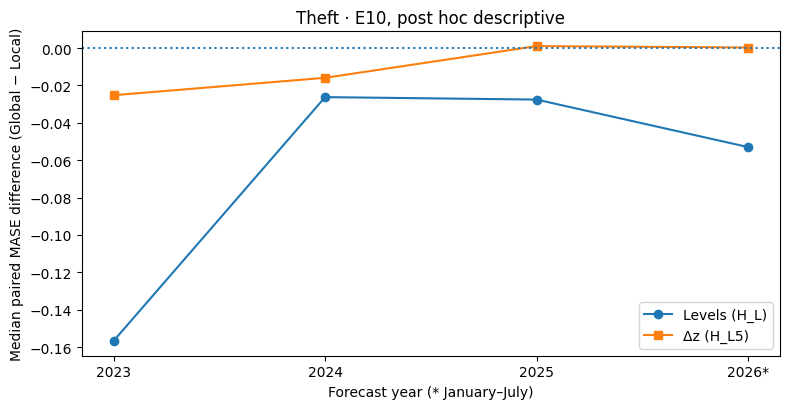

Fuente: e10 calculado desde los pronósticos. 2026 parcial. Evolución descriptiva, no explicación causal.
Datos de esta figura: fig4_anual_hurto_datos.csv


In [9]:
e10 = sp.by_year(main)
sp.write_csv(TAB / 'E10_anual.csv', e10)
display(sp.view_by_year(e10))
for target in sp.TARGETS:
    datos_grafico = e10[e10.target == target].copy()
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for form, marker, label in [('niveles', 'o', 'Levels (H_L)'), ('dz', 's', 'Δz (H_L5)')]:
        annual = datos_grafico[datos_grafico.formulation == form].sort_values('year')
        ax.plot(annual.year.astype(int), annual.median_diff_global_minus_local, marker=marker, label=label)
    ax.axhline(0, linestyle=':')
    ax.set_xticks([2023, 2024, 2025, 2026], ['2023', '2024', '2025', '2026*'])
    ax.set(title=f'{sp.TARGET_EN[target]} · E10, post hoc descriptive',
           xlabel='Forecast year (* January–July)', ylabel='Median paired MASE difference (Global − Local)')
    ax.legend()
    registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG, f'fig4_anual_{target.lower()}',
        'Fuente: e10 calculado desde los pronósticos. 2026 parcial. Evolución descriptiva, no explicación causal.',
        '04', '6. E10 anual'))

## 7. Sensibilidades y anexos registrados

Se calculan E3, E4, E5c, E7, E9 y los diagnósticos registrados. La tabla completa conserva todos los métodos,
incluidos aquellos con resultados desfavorables. No todos los análisis necesitan una figura.

**E3** compara Global con H_G entrenado sobre 42 distritos frente al entrenado sobre 43, evaluando ambos
sobre los mismos 42 distritos distintos de Santa María del Mar.

**E4** calcula el cambio primero en cada distrito, usando Local y Global en niveles con H_L:

$$
D_d=
\left(\operatorname{MASE}_{d,\mathrm{Global},\mathrm{post}}-
\operatorname{MASE}_{d,\mathrm{Local},\mathrm{post}}\right)
-
\left(\operatorname{MASE}_{d,\mathrm{Global},\mathrm{pre}}-
\operatorname{MASE}_{d,\mathrm{Local},\mathrm{pre}}\right).
$$

El resumen de E4 es la mediana de los 43 valores de $D_d$, no la resta de medianas grupales.
Pre comprende enero de 2023–octubre de 2024 (22 meses); post, noviembre de 2024–julio de 2026 (21 meses).
Se mantiene Q_d y no se atribuye causalmente el cambio al registro.

**E7** utiliza, para cada distrito y periodo, el cociente

$$
R_d=\frac{\operatorname{MASE}_{d,\mathrm{modelo}}}{\operatorname{MASE}_{d,\mathrm{naive1}}}.
$$

Si el denominador es cero, el cociente se declara no definido: no se le suma una constante.
El distrito permanece en los errores, las diferencias pareadas y los conteos que sí pueden calcularse.
La tabla informa cuántos cocientes son válidos.

In [10]:
ax_data = sp.annex(P, Q, panel, fc_all, main, MASE, config, TAB)
display(sp.view_annex(contrasts, ax_data))
e7 = pd.read_csv(TAB / 'E7_por_periodo.csv')
display(e7[e7.n_ratio_valid < e7.n_districts][['target', 'strategy', 'period', 'n_ratio_valid', 'n_districts']])

Mediana [IC95]  \
Análisis                                  Delito                            
E4 · cambio post − pre (Global − Local)   Robo    +0.070 [−0.004; +0.122]   
                                          Hurto   +0.019 [−0.031; +0.083]   
E3 · Global sin − con Santa María del Mar Robo    +0.006 [+0.001; +0.012]   
                                          Hurto   −0.003 [−0.010; +0.005]   
E5c · Local: Δz − niveles                 Robo    −0.099 [−0.137; −0.079]   
                                          Hurto   −0.099 [−0.125; −0.049]   
E5c · Global (H_G): Δz − niveles          Robo    +0.014 [−0.004; +0.037]   
                                          Hurto   −0.033 [−0.065; −0.016]   

                                                   p Holm  
Análisis                                  Delito           
E4 · cambio post − pre (Global − Local)   Robo      0.098  
                                          Hurto      0.53  
E3 · Global sin − con Santa María del Mar Robo       0.33  
                                          Hurto      0.86  
E5c · Local: Δz − niveles                 Robo    2.6e-09  
                                          Hurto     5e-07  
E5c · Global (H_G): Δz − niveles          Robo       0.15  
                                          Hurto    0.0047

,target,strategy,period,n_ratio_valid,n_districts
47,ROBO,global_HG,2026,42,43
51,ROBO,global_HL,2026,42,43
55,ROBO,global_dz_HG,2026,42,43
59,ROBO,global_dz_HL,2026,42,43
63,ROBO,local_HL,2026,42,43
67,ROBO,local_dz_HL,2026,42,43
71,ROBO,naive1,2026,42,43
75,ROBO,naive_seasonal,2026,42,43
79,ROBO,ridge_dz,2026,42,43
83,ROBO,ses,2026,42,43


### E4: curva mensual posterior al cambio, calculada desde los pares reales

Cada punto es la mediana entre distritos de la diferencia mensual de error absoluto escalado Global − Local.
La banda va del **primer al tercer cuartil distrital (Q1–Q3)**; muestra dispersión entre distritos y
**no es un intervalo de confianza**. El rango intercuartílico es $\mathrm{IQR}=Q_3-Q_1$.

$k=0$ corresponde a noviembre de 2024 y $k=20$ a julio de 2026. Esta curva mensual describe el periodo posterior;
no sustituye el contraste pre/post de E4. No se ajustan modelos nuevos ni se realizan pruebas mensuales adicionales.

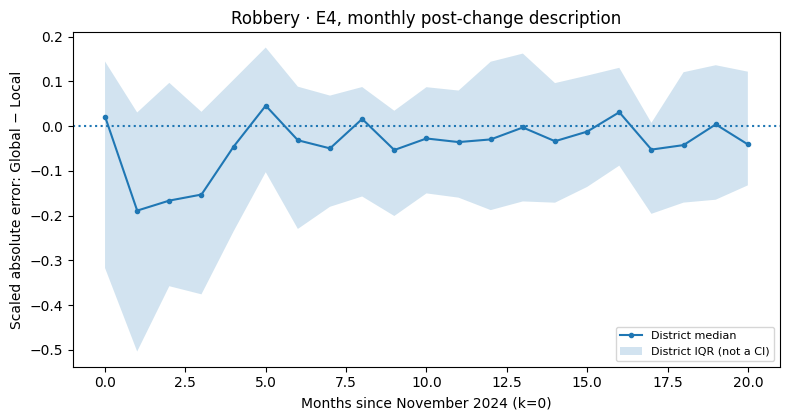

Fuente: errores mensuales de main, agrupados por target y mes. Banda IQR distrital, no IC. Descripción alrededor del cambio de registro; no efecto causal.
Datos de esta figura: figA1_E4_robo_datos.csv


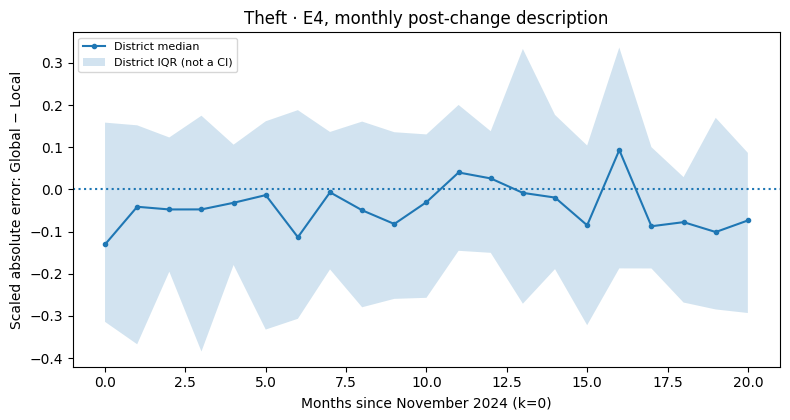

Fuente: errores mensuales de main, agrupados por target y mes. Banda IQR distrital, no IC. Descripción alrededor del cambio de registro; no efecto causal.
Datos de esta figura: figA1_E4_hurto_datos.csv


In [11]:
post = main[(main.forecast_month >= sp.BREAK_DATE) & main.strategy.isin(['local_HL', 'global_HL'])]
pares_mensuales = post.pivot(index=['target', 'UBIGEO', 'forecast_month'], columns='strategy', values='scaled_error')
pares_mensuales['delta'] = pares_mensuales.global_HL - pares_mensuales.local_HL
curva = pares_mensuales.reset_index().groupby(['target', 'forecast_month'], as_index=False).agg(
    median_delta=('delta', 'median'), q1=('delta', lambda s: s.quantile(.25)),
    q3=('delta', lambda s: s.quantile(.75)), n_districts=('UBIGEO', 'nunique'))
for target in sp.TARGETS:
    datos_grafico = curva[curva.target == target].sort_values('forecast_month').copy()
    datos_grafico['k'] = np.arange(len(datos_grafico))
    sp.require(len(datos_grafico) == 21 and datos_grafico.n_districts.eq(43).all(), 'Curva post-break incompleta.')
    fig, ax = plt.subplots(figsize=(8, 4.3))
    ax.plot(datos_grafico.k, datos_grafico.median_delta, marker='o', markersize=3, label='District median')
    ax.fill_between(datos_grafico.k, datos_grafico.q1, datos_grafico.q3, alpha=.2, label='District IQR (not a CI)')
    ax.axhline(0, linestyle=':')
    ax.set(title=f'{sp.TARGET_EN[target]} · E4, monthly post-change description',
           xlabel='Months since November 2024 (k=0)', ylabel='Scaled absolute error: Global − Local')
    ax.legend(fontsize=8)
    registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG, f'figA1_E4_{target.lower()}',
        'Fuente: errores mensuales de main, agrupados por target y mes. Banda IQR distrital, no IC. '
        'Descripción alrededor del cambio de registro; no efecto causal.', '04', '7. E4 mensual'))

## 8. Exportar la misma evidencia que se muestra

Las tablas del paper utilizan los mismos objetos calculados en las secciones anteriores. Cada figura exportada tiene
CSV, PNG, SVG y una descripción TXT. El índice identifica la notebook y la sección que la genera.
Los gráficos mostrados se construyen con los datos de esta ejecución; no se cargan imágenes estáticas de otra corrida.

Este reanálisis de pronósticos registrados no acredita una reproducción independiente del entrenamiento en otro equipo.
Las tablas resumen conservadas en `evidencia_registrada/corrida_colab_2026-11-02/` tampoco bastan para acreditarla.

**Para alumnos:** explica una fila de E1 y una figura indicando datos de origen, signo y limitaciones.
**Para revisores:** contrasta el CSV de la figura con la tabla y el manifiesto; conserva el estatus de cada análisis.

In [12]:
tablas_paper = sp.save_paper_tables(P, PAPER / 'tablas', contrasts, e8, e10, ax_data)
display(sf.guardar_indice(registros_figuras, FIG))
sp.save_manifest(P.analysis, ENV, [f for f in P.analysis.rglob('*') if f.is_file()],
    mode='reanalisis_sin_entrenamiento',
    forecasts_sha256=sp.sha256_file(P.forecasts), config_sha256=sp.sha256_file(P.config),
    scores_sha256=sp.sha256_file(P.scores),
    code_sha256={n: sp.sha256_file(PROJECT_DIR / n) for n in ['sidpol.py', 'sidpol_figuras.py']})
print('Tablas del paper:', ', '.join(tablas_paper))
print('Análisis finalizado. Todas las figuras mostradas se generaron en esta ejecución.')

,notebook,seccion,figura,datos,filas
0,04,3. E1/E1b,fig1_E1_robo.png,fig1_E1_robo_datos.csv,2
1,04,3. E1/E1b,fig1_E1_hurto.png,fig1_E1_hurto_datos.csv,2
2,04,4. Referencias simples,fig2_referencias_robo.png,fig2_referencias_robo_datos.csv,6
3,04,4. Referencias simples,fig2_referencias_hurto.png,fig2_referencias_hurto_datos.csv,6
4,04,5. E5 por distrito,fig3_E5_distritos_robo.png,fig3_E5_distritos_robo_datos.csv,43
5,04,5. E5 por distrito,fig3_E5_distritos_hurto.png,fig3_E5_distritos_hurto_datos.csv,43
6,04,6. E10 anual,fig4_anual_robo.png,fig4_anual_robo_datos.csv,8
7,04,6. E10 anual,fig4_anual_hurto.png,fig4_anual_hurto_datos.csv,8
8,04,7. E4 mensual,figA1_E4_robo.png,figA1_E4_robo_datos.csv,21
9,04,7. E4 mensual,figA1_E4_hurto.png,figA1_E4_hurto_datos.csv,21


Tablas del paper: table1_strategies.md, table2_global_vs_local.md, tableA1_e4_e3.md, tableA2_all_strategies.md, tableA3_annual.md, tableA4_dz_vs_levels.md
Análisis finalizado. Todas las figuras mostradas se generaron en esta ejecución.
